# Descripción

La compañía de seguros Sure Tomorrow quiere resolver varias tareas con la ayuda de machine learning y te pide que evalúes esa posibilidad.

- Tarea 1: encontrar clientes que sean similares a un cliente determinado. Esto ayudará a los agentes de la compañía con el marketing.
- Tarea 2: predecir la probabilidad de que un nuevo cliente reciba una prestación del seguro. ¿Puede un modelo de predictivo funcionar mejor que un modelo dummy?
- Tarea 3: predecir el número de prestaciones de seguro que un nuevo cliente pueda recibir utilizando un modelo de regresión lineal.
- Tarea 4: proteger los datos personales de los clientes sin afectar al modelo del ejercicio anterior. Es necesario desarrollar un algoritmo de transformación de datos que dificulte la recuperación de la información personal si los datos caen en manos equivocadas. Esto se denomina enmascaramiento u ofuscación de datos. Pero los datos deben protegerse de tal manera que no se vea afectada la calidad de los modelos de machine learning. No es necesario elegir el mejor modelo, basta con demostrar que el algoritmo funciona correctamente.


# Preprocesamiento y exploración de datos

## Inicialización

In [1]:
import numpy as np
import pandas as pd

import seaborn as sns

import sklearn.linear_model
import sklearn.metrics
import sklearn.neighbors
import sklearn.preprocessing

from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors

from IPython.display import display

## Carga de datos

Carga los datos y haz una revisión básica para comprobar que no hay problemas obvios.

In [2]:
df = pd.read_csv('insurance_us.csv')

Renombramos las columnas para que el código se vea más coherente con su estilo.

In [3]:
df = df.rename(columns={'Gender': 'gender', 'Age': 'age', 'Salary': 'income', 'Family members': 'family_members', 'Insurance benefits': 'insurance_benefits'})

In [4]:
df.sample(10)

,gender,age,income,family_members,insurance_benefits
4495,0,35.0,42900.0,1,0
259,0,29.0,38400.0,2,0
2692,0,40.0,31300.0,1,0
2906,1,24.0,48300.0,1,0
2695,1,33.0,37500.0,4,0
696,1,34.0,30700.0,0,0
2347,0,22.0,42800.0,4,0
1562,1,31.0,54700.0,0,0
3273,1,19.0,51200.0,0,0
4266,0,32.0,50400.0,1,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              5000 non-null   int64  
 1   age                 5000 non-null   float64
 2   income              5000 non-null   float64
 3   family_members      5000 non-null   int64  
 4   insurance_benefits  5000 non-null   int64  
dtypes: float64(2), int64(3)
memory usage: 195.4 KB


In [6]:
# Comprobamos que las edades originales sean números enteros
edades_con_decimales = (df['age'] % 1 != 0).sum()

print('Edades con decimales antes de convertir:', edades_con_decimales)

# Convertimos las edades únicamente si no tienen decimales
if edades_con_decimales == 0:
    df['age'] = df['age'].astype(int)
    print('Conversión realizada correctamente.')
else:
    print('Revisar edades con decimales antes de convertir.')

Edades con decimales antes de convertir: 0
Conversión realizada correctamente.


In [7]:
print(df['age'].dtype)
print(df['age'].head(10))

int64
0    41
1    46
2    29
3    21
4    28
5    43
6    39
7    25
8    36
9    32
Name: age, dtype: int64


In [8]:
display(df.describe())

,gender,age,income,family_members,insurance_benefits
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.499000,30.952800,39916.360000,1.194200,0.148000
std,0.500049,8.440807,9900.083569,1.091387,0.463183
min,0.000000,18.000000,5300.000000,0.000000,0.000000
25%,0.000000,24.000000,33300.000000,0.000000,0.000000
50%,0.000000,30.000000,40200.000000,1.000000,0.000000
75%,1.000000,37.000000,46600.000000,2.000000,0.000000
max,1.000000,65.000000,79000.000000,6.000000,5.000000


In [9]:
# Revisamos los valores mínimos y máximos
columnas_numericas = [
    'age',
    'income',
    'family_members',
    'insurance_benefits'
]

print('Rangos de las variables:')
display(df[columnas_numericas].agg(['min', 'max']))

# Identificamos valores que podrían ser inválidos
print('\nValores fuera de rangos básicos:')

print('Edades negativas:', (df['age'] < 0).sum())
print('Ingresos negativos:', (df['income'] < 0).sum())
print('Familiares negativos:', (df['family_members'] < 0).sum())
print('Beneficios negativos:', (df['insurance_benefits'] < 0).sum())

# Detectamos posibles valores atípicos mediante el método IQR
print('\nPosibles valores atípicos según IQR:')

for columna in columnas_numericas:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    atipicos = (
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    ).sum()

    print(columna, ':', atipicos)

Rangos de las variables:


,age,income,family_members,insurance_benefits
min,18,5300.0,0,0
max,65,79000.0,6,5



Valores fuera de rangos básicos:
Edades negativas: 0
Ingresos negativos: 0
Familiares negativos: 0
Beneficios negativos: 0

Posibles valores atípicos según IQR:
age : 12
income : 37
family_members : 7
insurance_benefits : 564


### Análisis de rangos y valores atípicos

Se revisaron los valores mínimos, máximos y posibles observaciones atípicas de las variables numéricas del conjunto de datos.

**1. Validación de rangos**

Los resultados fueron:

| Variable | Mínimo | Máximo |
|---|---:|---:|
| Edad | 18 | 65 |
| Ingresos | 5,300 | 79,000 |
| Número de familiares | 0 | 6 |
| Beneficios de seguro | 0 | 5 |

No se encontraron valores negativos en ninguna de estas cuatro variables. Los rangos observados son plausibles y no muestran errores evidentes.

**2. Identificación de valores atípicos**

Se utilizó el método del rango intercuartílico (IQR), que identifica observaciones fuera del intervalo:

$$
[Q_1-1.5\,IQR,\;Q_3+1.5\,IQR]
$$

Los resultados fueron:

| Variable | Posibles valores atípicos |
|---|---:|
| Edad | 12 |
| Ingresos | 37 |
| Número de familiares | 7 |
| Beneficios de seguro | 564 |

Los valores atípicos identificados mediante IQR no necesariamente representan errores. Pueden corresponder a clientes con características menos frecuentes.

En particular, `insurance_benefits` presenta una concentración elevada de valores iguales a cero. Por esta razón, el primer y tercer cuartil son cero, y el método IQR clasifica como atípicos todos los valores positivos.

Los 564 casos positivos son observaciones relevantes para el objetivo del proyecto. Eliminarlos provocaría la pérdida de todos los registros de clientes que recibieron beneficios y afectaría gravemente la tarea de clasificación.

**3. Decisión de tratamiento**

Se decidió conservar los registros identificados como atípicos debido a que:

- No presentan inconsistencias evidentes en los rangos analizados.
- No se dispone de evidencia que permita clasificarlos como errores de captura.
- Los casos positivos de beneficios son necesarios para desarrollar y evaluar los modelos.

**Conclusión**

El análisis de rangos y valores atípicos no proporciona motivos suficientes para eliminar o modificar observaciones.

Se conservará el conjunto de datos completo para las siguientes tareas, reconociendo que la presencia de valores poco frecuentes y el desequilibrio de la variable objetivo son aspectos importantes al interpretar los resultados.

In [10]:
print('Valores faltantes por columna:')
print(df.isna().sum())

print('\nFilas duplicadas:')
print(df.duplicated().sum())

Valores faltantes por columna:
gender                0
age                   0
income                0
family_members        0
insurance_benefits    0
dtype: int64

Filas duplicadas:
153


In [11]:
duplicados = df[df.duplicated(keep=False)]

print('Total de filas involucradas en duplicados:', len(duplicados))

display(duplicados.sort_values(
    by=['gender', 'age', 'income', 'family_members']
).head(20))

Total de filas involucradas en duplicados: 300


,gender,age,income,family_members,insurance_benefits
1751,0,19,38600.0,0,0
3268,0,19,38600.0,0,0
851,0,19,51700.0,0,0
2853,0,19,51700.0,0,0
688,0,20,35800.0,0,0
785,0,20,35800.0,0,0
1313,0,20,36800.0,0,0
2654,0,20,36800.0,0,0
3918,0,20,41500.0,2,0
4125,0,20,41500.0,2,0


### Revisión de registros duplicados

Durante la revisión inicial del conjunto de datos se identificaron los siguientes resultados:

- **Registros totales:** 5,000.
- **Valores faltantes:** 0.
- **Registros duplicados adicionales:** 153.
- **Filas involucradas en duplicados:** 300.

El dataset no contiene identificadores únicos que permitan determinar si los registros duplicados corresponden a errores de captura o a clientes diferentes con características idénticas.

Por esta razón, **se decidió conservar los registros duplicados**, ya que eliminarlos sin evidencia suficiente podría provocar la pérdida de observaciones válidas.

Esta decisión se tendrá en cuenta durante la construcción y evaluación de los modelos de Machine Learning, especialmente al dividir los datos en conjuntos de entrenamiento y prueba.

## Análisis exploratorio de datos

Vamos a comprobar rápidamente si existen determinados grupos de clientes observando el gráfico de pares.

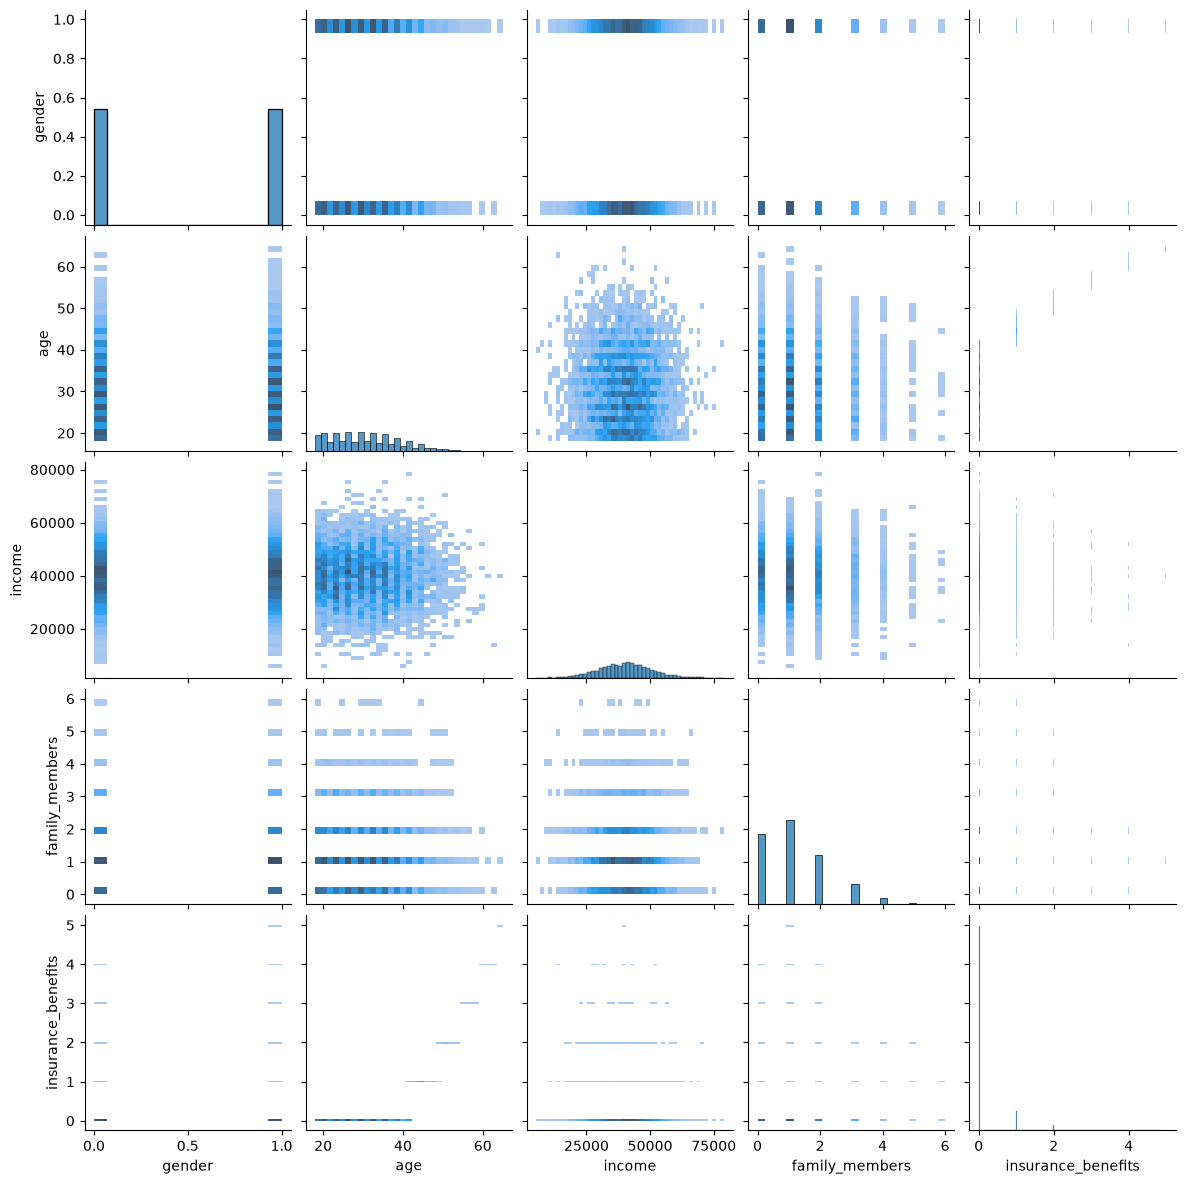

In [12]:
g = sns.pairplot(df, kind='hist')
g.fig.set_size_inches(12, 12)

De acuerdo, es un poco complicado detectar grupos obvios (clústeres) ya que es difícil combinar diversas variables simultáneamente (para analizar distribuciones multivariadas). Ahí es donde LA y ML pueden ser bastante útiles.

### Conclusiones del análisis exploratorio

El análisis exploratorio mediante gráficos de pares permite identificar las siguientes características del conjunto de datos:

- **Distribución por género:** se observan registros de ambas categorías, sin una separación visual clara respecto a las demás variables.
- **Edad:** la mayor concentración de clientes se encuentra aproximadamente entre los 20 y 40 años.
- **Ingresos:** gran parte de los clientes presenta ingresos cercanos al intervalo de 30,000 a 50,000.
- **Número de familiares:** predominan los clientes con pocos familiares registrados, especialmente entre 0 y 2.
- **Beneficios de seguro:** la mayoría de las observaciones corresponde a clientes que no han recibido beneficios.

Se observa una asociación visual entre la edad y el número de beneficios de seguro: los clientes con mayor cantidad de beneficios tienden a tener edades más elevadas. Esta relación es exploratoria y no implica causalidad.

**Conclusión general:** no se identifican grupos de clientes claramente separados mediante la inspección visual de todas las variables. Será necesario utilizar métodos de distancia y algoritmos de Machine Learning para analizar similitudes entre clientes y construir modelos predictivos.

Además, la concentración de observaciones con cero beneficios sugiere un posible desequilibrio de clases, que deberá cuantificarse antes de evaluar el modelo de clasificación.

# Tarea 1. Clientes similares

En el lenguaje de ML, es necesario desarrollar un procedimiento que devuelva los k vecinos más cercanos (objetos) para un objeto dado basándose en la distancia entre los objetos.

Es posible que quieras revisar las siguientes lecciones (capítulo -> lección)
- Distancia entre vectores -> Distancia euclidiana
- Distancia entre vectores -> Distancia Manhattan

Para resolver la tarea, podemos probar diferentes métricas de distancia.

Escribe una función que devuelva los k vecinos más cercanos para un $n^{th}$ objeto basándose en una métrica de distancia especificada. A la hora de realizar esta tarea no debe tenerse en cuenta el número de prestaciones de seguro recibidas.

Puedes utilizar una implementación ya existente del algoritmo kNN de scikit-learn (consulta [el enlace](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html#sklearn.neighbors.NearestNeighbors)) o tu propia implementación.

Pruébalo para cuatro combinaciones de dos casos
- Escalado
  - los datos no están escalados
  - los datos se escalan con el escalador [MaxAbsScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MaxAbsScaler.html)
- Métricas de distancia
  - Euclidiana
  - Manhattan

Responde a estas preguntas:
- ¿El hecho de que los datos no estén escalados afecta al algoritmo kNN? Si es así, ¿cómo se manifiesta?
- ¿Qué tan similares son los resultados al utilizar la métrica de distancia Manhattan (independientemente del escalado)?

In [13]:
feature_names = ['gender', 'age', 'income', 'family_members']

In [14]:
def get_knn(df, n, k, metric):
    
    """
    Devuelve los k vecinos más cercanos

    :param df: DataFrame de pandas utilizado para encontrar objetos similares dentro del mismo lugar
    :param n: número de objetos para los que se buscan los vecinos más cercanos
    :param k: número de vecinos más cercanos a devolver
    :param métrica: nombre de la métrica de distancia
    """

    nbrs = NearestNeighbors(n_neighbors=k, metric=metric).fit(df[feature_names])
    nbrs_distances, nbrs_indices = nbrs.kneighbors(df.iloc[[n]][feature_names],n_neighbors=k,return_distance=True)

    
    df_res = pd.concat([
        df.iloc[nbrs_indices[0]], 
        pd.DataFrame(nbrs_distances.T, index=nbrs_indices[0], columns=['distance'])
        ], axis=1)
    
    return df_res

Escalar datos.

In [15]:
# Seleccionamos las características que queremos escalar
feature_names = ['gender', 'age', 'income', 'family_members']

# Creamos y ajustamos el escalador
transformer_mas = sklearn.preprocessing.MaxAbsScaler()
transformer_mas.fit(df[feature_names].to_numpy())

# Creamos una copia para conservar los datos originales
df_scaled = df.copy()

# Convertimos las columnas a decimales antes de escalarlas
df_scaled[feature_names] = df_scaled[feature_names].astype(float)

# Aplicamos el escalado a la copia
df_scaled.loc[:, feature_names] = transformer_mas.transform(
    df[feature_names].to_numpy()
)

print('Escalado completado correctamente')
display(df_scaled[feature_names].head())


Escalado completado correctamente


,gender,age,income,family_members
0,1.0,0.630769,0.627848,0.166667
1,0.0,0.707692,0.481013,0.166667
2,0.0,0.446154,0.265823,0.000000
3,0.0,0.323077,0.527848,0.333333
4,1.0,0.430769,0.330380,0.000000


In [16]:
df_scaled.sample(5)

,gender,age,income,family_members,insurance_benefits
810,0.0,0.307692,0.445570,0.000000,0
1331,0.0,0.553846,0.355696,0.000000,0
1662,1.0,0.292308,0.462025,0.166667,0
2534,0.0,0.400000,0.591139,0.000000,0
744,1.0,0.769231,0.654430,0.166667,2


Ahora, vamos a obtener registros similares para uno determinado, para cada combinación

In [17]:
get_knn(df, n=0, k=5, metric='euclidean')

,gender,age,income,family_members,insurance_benefits,distance
0,1,41,49600.0,1,0,0.000000
2022,1,41,49600.0,0,0,1.000000
1225,0,42,49600.0,0,1,1.732051
4031,1,44,49600.0,2,1,3.162278
3424,0,38,49600.0,0,0,3.316625


In [18]:
get_knn(df, n=0, k=5, metric='manhattan')

,gender,age,income,family_members,insurance_benefits,distance
0,1,41,49600.0,1,0,0.0
2022,1,41,49600.0,0,0,1.0
1225,0,42,49600.0,0,1,3.0
4031,1,44,49600.0,2,1,4.0
815,1,37,49600.0,2,0,5.0


In [19]:
get_knn(df_scaled, n=0, k=5, metric='euclidean')

,gender,age,income,family_members,insurance_benefits,distance
0,1.0,0.630769,0.627848,0.166667,0,0.000000
2689,1.0,0.630769,0.634177,0.166667,0,0.006329
133,1.0,0.615385,0.636709,0.166667,0,0.017754
4869,1.0,0.646154,0.637975,0.166667,1,0.018418
3275,1.0,0.646154,0.651899,0.166667,1,0.028550


In [20]:
get_knn(df_scaled, n=0, k=5, metric='manhattan')

,gender,age,income,family_members,insurance_benefits,distance
0,1.0,0.630769,0.627848,0.166667,0,0.000000
2689,1.0,0.630769,0.634177,0.166667,0,0.006329
133,1.0,0.615385,0.636709,0.166667,0,0.024245
4869,1.0,0.646154,0.637975,0.166667,1,0.025511
2103,1.0,0.630769,0.596203,0.166667,0,0.031646


Respuestas a las preguntas

**1. ¿El hecho de que los datos no estén escalados afecta al algoritmo kNN? Si es así, ¿cómo se manifiesta?**

Sí. El escalado afecta considerablemente a la identificación de vecinos cercanos.

Al utilizar los datos originales, la variable `income` tiene valores numéricos mucho mayores que las demás características. Por ello, las diferencias de ingresos pueden dominar el cálculo de distancias y reducir la influencia de variables como la edad, el género y el número de familiares.

En nuestra comparación para el cliente con índice `0`, los vecinos encontrados con distancia euclidiana cambiaron de `[0, 2022, 1225, 4031, 3424]` sin escalado a `[0, 2689, 133, 4869, 3275]` después de aplicar `MaxAbsScaler`.

Esto demuestra que el escalado modifica qué clientes considera similares el algoritmo kNN. Por tanto, es importante considerar las escalas de las características antes de utilizar métricas de distancia.

**2. ¿Qué tan similares son los resultados al utilizar la métrica de distancia Manhattan, independientemente del escalado?**

Los resultados de las métricas euclidiana y Manhattan son muy similares cuando se comparan dentro de una misma condición de escalado.

- **Sin escalado:** ambas métricas identificaron los mismos cinco vecinos en exactamente el mismo orden: `[0, 2022, 1225, 4031, 3424]`.
- **Con escalado:** ambas métricas coincidieron en cuatro de los cinco registros. Los vecinos euclidianos fueron `[0, 2689, 133, 4869, 3275]`, mientras que Manhattan identificó `[0, 2689, 133, 4869, 3365]`.

Aunque las distancias calculadas son distintas, ambas métricas ofrecen resultados similares para el cliente analizado.

**Conclusión:** en este ejemplo, el escalado tuvo un efecto mayor sobre la selección de vecinos que el cambio entre las métricas euclidiana y Manhattan. Sin embargo, estos resultados corresponden a un cliente específico y no necesariamente representan el comportamiento de todos los clientes del dataset.

# Tarea 2. ¿Es probable que el cliente reciba una prestación del seguro?

En términos de machine learning podemos considerarlo como una tarea de clasificación binaria.

Con el valor de `insurance_benefits` superior a cero como objetivo, evalúa si el enfoque de clasificación kNN puede funcionar mejor que el modelo dummy.

Instrucciones:
- Construye un clasificador basado en KNN y mide su calidad con la métrica F1 para k=1...10 tanto para los datos originales como para los escalados. Sería interesante observar cómo k puede influir en la métrica de evaluación y si el escalado de los datos provoca alguna diferencia. Puedes utilizar una implementación ya existente del algoritmo de clasificación kNN de scikit-learn (consulta [el enlace](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)) o tu propia implementación.
- Construye un modelo dummy que, en este caso, es simplemente un modelo aleatorio. Debería devolver "1" con cierta probabilidad. Probemos el modelo con cuatro valores de probabilidad: 0, la probabilidad de pagar cualquier prestación del seguro, 0.5, 1.

La probabilidad de pagar cualquier prestación del seguro puede definirse como

$$
P\{\text{prestación de seguro recibida}\}=\frac{\text{número de clientes que han recibido alguna prestación de seguro}}{\text{número total de clientes}}.
$$

Divide todos los datos correspondientes a las etapas de entrenamiento/prueba respetando la proporción 70:30.

In [21]:
df['insurance_benefits_received'] = (df['insurance_benefits'] > 0).astype(int)

In [22]:
print(df['insurance_benefits_received'].value_counts())

insurance_benefits_received
0    4436
1     564
Name: count, dtype: int64


In [23]:
def eval_classifier(y_true, y_pred):
    
    f1_score = sklearn.metrics.f1_score(y_true, y_pred)
    print(f'F1: {f1_score:.2f}')
    
# si tienes algún problema con la siguiente línea, reinicia el kernel y ejecuta el cuaderno de nuevo
    cm = sklearn.metrics.confusion_matrix(y_true, y_pred, normalize='all')
    print('Matriz de confusión')
    print(cm)

In [24]:
# generar la salida de un modelo aleatorio

def rnd_model_predict(P, size, seed=42):

    rng = np.random.default_rng(seed=seed)
    return rng.binomial(n=1, p=P, size=size)

In [25]:
for P in [0, df['insurance_benefits_received'].sum() / len(df), 0.5, 1]:

    print(f'La probabilidad: {P:.2f}')

    y_pred_rnd = rnd_model_predict(P,
    len(df['insurance_benefits_received'])) 
        
    eval_classifier(df['insurance_benefits_received'], y_pred_rnd)
    
    print()


La probabilidad: 0.00


F1: 0.00
Matriz de confusión
[[0.8872 0.    ]
 [0.1128 0.    ]]

La probabilidad: 0.11
F1: 0.12
Matriz de confusión
[[0.7914 0.0958]
 [0.0994 0.0134]]

La probabilidad: 0.50
F1: 0.20
Matriz de confusión
[[0.456  0.4312]
 [0.053  0.0598]]

La probabilidad: 1.00
F1: 0.20
Matriz de confusión
[[0.     0.8872]
 [0.     0.1128]]



In [26]:
# Características utilizadas para predecir
X = df[feature_names]

# Objetivo binario: recibió o no beneficios
y = df['insurance_benefits_received']

print('Dimensiones de las características:', X.shape)
print('Dimensiones del objetivo:', y.shape)

Dimensiones de las características: (5000, 4)
Dimensiones del objetivo: (5000,)


In [27]:
from sklearn.model_selection import GroupShuffleSplit

# Agrupamos registros que tengan las mismas características
groups = pd.factorize(
    pd.MultiIndex.from_frame(X)
)[0]

# Dividimos los datos procurando un 70% / 30%
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(X, y, groups=groups)

)


# Construimos los conjuntos de entrenamiento y prueba
X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

print('Clientes de entrenamiento:', len(X_train))
print('Clientes de prueba:', len(X_test))

print('\nProporción positiva en entrenamiento:', y_train.mean())
print('Proporción positiva en prueba:', y_test.mean())

Clientes de entrenamiento: 3503
Clientes de prueba: 1497

Proporción positiva en entrenamiento: 0.11561518698258635
Proporción positiva en prueba: 0.1062124248496994


In [28]:
# Reconstruimos los registros de entrenamiento
train_rows = X_train.copy()
train_rows['target'] = y_train

# Reconstruimos los registros de prueba
test_rows = X_test.copy()
test_rows['target'] = y_test

# Buscamos registros idénticos entre ambos conjuntos
duplicados_cruzados = test_rows.merge(
    train_rows.drop_duplicates(),
    on=feature_names + ['target'],
    how='inner'
)

print('Registros de prueba idénticos a registros de entrenamiento:',
      len(duplicados_cruzados))

print('Porcentaje del conjunto de prueba:',
      round(len(duplicados_cruzados) / len(X_test) * 100, 2), '%')

Registros de prueba idénticos a registros de entrenamiento: 0
Porcentaje del conjunto de prueba: 0.0 %


In [29]:
from sklearn.preprocessing import MaxAbsScaler

# Creamos el escalador
scaler = MaxAbsScaler()

# Ajustamos y transformamos los datos de entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# Transformamos los datos de prueba
X_test_scaled = scaler.transform(X_test)

print('Entrenamiento escalado:', X_train_scaled.shape)
print('Prueba escalada:', X_test_scaled.shape)

Entrenamiento escalado: (3503, 4)
Prueba escalada: (1497, 4)


In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MaxAbsScaler
import pandas as pd

# Creamos 5 particiones para validar los modelos
cv = GroupKFold(n_splits=5)

# Utilizamos únicamente los grupos del conjunto de entrenamiento
groups_train = groups[train_indices]

# Lista para guardar los resultados
results_knn = []

# Probamos valores de k desde 1 hasta 10
for k in range(1, 11):

    # MODELO 1: Datos originales sin escalar
    model_original = KNeighborsClassifier(n_neighbors=k)

    scores_original = cross_val_score(
        model_original,
        X_train,
        y_train,
        cv=cv,
        groups=groups_train,
        scoring='f1'
    )

    # MODELO 2: Datos escalados
    # El escalador se ajusta dentro de cada partición
    model_scaled = make_pipeline(
        MaxAbsScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores_scaled = cross_val_score(
        model_scaled,
        X_train,
        y_train,
        cv=cv,
        groups=groups_train,
        scoring='f1'
    )

    # Guardamos el promedio F1 de las 5 particiones
    results_knn.append([
        k,
        scores_original.mean(),
        scores_scaled.mean()
    ])

# Creamos una tabla comparativa
results_knn_df = pd.DataFrame(
    results_knn,
    columns=['k', 'F1 CV sin escalar', 'F1 CV escalado']
)

display(results_knn_df)

# Seleccionamos el mejor valor de k usando validación cruzada
best_k = int(
    results_knn_df.loc[
        results_knn_df['F1 CV escalado'].idxmax(),
        'k'
    ]
)

print('Mejor k según validación cruzada:', best_k)

,k,F1 CV sin escalar,F1 CV escalado
0,1,0.569165,0.927416
1,2,0.231321,0.893868
2,3,0.276615,0.918989
3,4,0.076428,0.893464
4,5,0.088911,0.907479
5,6,0.060359,0.883629
6,7,0.064733,0.910322
7,8,0.056296,0.885159
8,9,0.073640,0.895644
9,10,0.024385,0.866785


Mejor k según validación cruzada: 1


In [31]:
# Evaluamos en el conjunto de prueba el mejor modelo seleccionado por validación cruzada
best_knn = KNeighborsClassifier(n_neighbors=best_k)

# Entrenamos con los datos escalados de entrenamiento
best_knn.fit(X_train_scaled, y_train)

# Predecimos sobre el conjunto de prueba
best_predictions = best_knn.predict(X_test_scaled)

print(f'MODELO kNN ESCALADO (k={best_k})')
eval_classifier(y_test, best_predictions)

# Creamos un modelo dummy sobre el mismo conjunto de prueba
dummy_predictions = rnd_model_predict(
    P=y_train.mean(),
    size=len(y_test)
)

print('\nMODELO DUMMY')
eval_classifier(y_test, dummy_predictions)

MODELO kNN ESCALADO (k=1)
F1: 0.95
Matriz de confusión
[[0.88710755 0.00668003]
 [0.00467602 0.10153641]]

MODELO DUMMY
F1: 0.12
Matriz de confusión
[[0.78824315 0.10554442]
 [0.09218437 0.01402806]]


### Conclusiones de la Tarea 2: Clasificación binaria

El objetivo de esta tarea fue predecir si un cliente recibiría al menos una prestación de seguro, utilizando un clasificador kNN y comparándolo con un modelo dummy aleatorio.

**Distribución de clases**

El conjunto de datos contiene 5,000 registros, de los cuales 4,436 corresponden a clientes que no recibieron beneficios y 564 a clientes que recibieron al menos uno.

Esto representa un 88.72% de casos negativos y un 11.28% de casos positivos, por lo que existe un desequilibrio considerable de clases. Para evaluar los clasificadores se utilizó la métrica F1.

**Preparación de los datos**

Se dividieron los registros aproximadamente en un 70% para entrenamiento y un 30% para prueba, utilizando `GroupShuffleSplit`.

La división resultante fue de 3,503 registros de entrenamiento y 1,497 de prueba.

Se agruparon los registros con características idénticas para evitar que aparecieran simultáneamente en ambos conjuntos. La comprobación posterior confirmó que existían cero coincidencias exactas entre entrenamiento y prueba.

**Selección del modelo mediante validación cruzada**

Se evaluaron valores de `k` entre 1 y 10 mediante validación cruzada de cinco particiones utilizando `GroupKFold`.

El escalado se incorporó mediante un `Pipeline` con `MaxAbsScaler`, de modo que se ajustó únicamente con los registros de entrenamiento de cada partición.

Los mejores resultados promedio fueron:

| Configuración | Mejor k | F1 promedio de validación cruzada |
|---|---:|---:|
| Datos originales | 1 | 0.5989 |
| Datos escalados | 1 | 0.9283 |

La selección final fue `k=1`, utilizando las características escaladas.

**Evaluación en el conjunto de prueba**

El clasificador seleccionado obtuvo un F1 aproximado de **0.95** sobre el conjunto de prueba.

En comparación, el modelo dummy aleatorio, evaluado sobre los mismos registros, obtuvo un F1 aproximado de **0.12**.

Esto muestra que el clasificador kNN es considerablemente más eficaz que generar predicciones aleatorias para identificar clientes que recibieron beneficios.

**¿Puede un modelo entrenado funcionar peor que un modelo dummy?**

Sí. Un modelo entrenado puede producir resultados inferiores a los de un modelo dummy si las características son poco informativas, los hiperparámetros son inadecuados, existe sobreajuste o los datos de entrenamiento no representan adecuadamente los casos que se desean predecir.

Entrenar un modelo no garantiza automáticamente mejores resultados.

**Limitaciones metodológicas**

La agrupación evitó coincidencias exactas de características entre entrenamiento y prueba, reduciendo el riesgo de evaluaciones optimistas por registros duplicados.

La selección del valor de `k` se realizó mediante validación cruzada exclusivamente sobre el entrenamiento. Sin embargo, durante el desarrollo del proyecto ya se habían consultado resultados de prueba de configuraciones anteriores, por lo que la evaluación debe interpretarse con esa limitación.

Además, los datos no contienen identificadores únicos que permitan distinguir con certeza entre clientes distintos que comparten características.

**Conclusión general**

El escalado fue fundamental para mejorar el rendimiento de kNN, debido a que las características originales presentan magnitudes muy diferentes.

El modelo con datos escalados y `k=1` consiguió un F1 elevado y superó ampliamente al modelo dummy.

Los resultados respaldan la utilidad del algoritmo para esta tarea, aunque sería recomendable comprobar su capacidad de generalización con datos nuevos e independientes antes de implementarlo en un entorno real.

# Tarea 3. Regresión (con regresión lineal)

Con `insurance_benefits` como objetivo, evalúa cuál sería la RECM de un modelo de regresión lineal.

Construye tu propia implementación de regresión lineal. Para ello, recuerda cómo está formulada la solución de la tarea de regresión lineal en términos de LA. Comprueba la RECM tanto para los datos originales como para los escalados. ¿Puedes ver alguna diferencia en la RECM con respecto a estos dos casos?

Denotemos
- $X$: matriz de características; cada fila es un caso, cada columna es una característica, la primera columna está formada por unidades
- $y$ — objetivo (un vector)
- $\hat{y}$ — objetivo estimado (un vector)
- $w$ — vector de pesos

La tarea de regresión lineal en el lenguaje de las matrices puede formularse así:

$$
y = Xw
$$

El objetivo de entrenamiento es entonces encontrar esa $w$ w que minimice la distancia L2 (ECM) entre $Xw$ y $y$:

$$
\min_w d_2(Xw, y) \quad \text{or} \quad \min_w \text{MSE}(Xw, y)
$$

Parece que hay una solución analítica para lo anteriormente expuesto:

$$
w = (X^T X)^{-1} X^T y
$$

La fórmula anterior puede servir para encontrar los pesos $w$ y estos últimos pueden utilizarse para calcular los valores predichos

$$
\hat{y} = X_{val}w
$$

Divide todos los datos correspondientes a las etapas de entrenamiento/prueba respetando la proporción 70:30. Utiliza la métrica RECM para evaluar el modelo.

In [32]:
class MyLinearRegression:

    def __init__(self):
        self.weights = None

    def fit(self, X, y):

        # Añadir una columna de unos
        X2 = np.append(np.ones([len(X), 1]), X, axis=1)

        # Calcular los pesos de la regresión lineal
        self.weights = np.linalg.inv(X2.T @ X2) @ X2.T @ y

    def predict(self, X):

        # Añadir una columna de unos
        X2 = np.append(np.ones([len(X), 1]), X, axis=1)

        # Calcular las predicciones
        y_pred = X2 @ self.weights

        return y_pred

In [33]:
def eval_regressor(y_true, y_pred):

    # Calculamos la raíz del error cuadrático medio
    rmse = np.sqrt(sklearn.metrics.mean_squared_error(y_true, y_pred))
    print(f'RMSE: {rmse:.2f}')

    # Calculamos R2 sin aplicar raíz cuadrada
    r2_score = sklearn.metrics.r2_score(y_true, y_pred)
    print(f'R2: {r2_score:.2f}') 

In [34]:
# Preparamos las características y la variable objetivo
X = df[['age', 'gender', 'income', 'family_members']].to_numpy()
y = df['insurance_benefits'].to_numpy()

# Reutilizamos los índices de la división agrupada de la Tarea 2
# Así evitamos separar registros con características idénticas
X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

# Comprobamos el tamaño de los conjuntos
print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)

# Creamos nuestro modelo de regresión lineal
lr = MyLinearRegression()

# Entrenamos el modelo
lr.fit(X_train, y_train)

# Mostramos los pesos calculados
print('\nPesos de la regresión:')
print(lr.weights)

# Realizamos predicciones sobre el conjunto de prueba
y_test_pred = lr.predict(X_test)

# Evaluamos el modelo
print('\nRegresión lineal con datos originales')
eval_regressor(y_test, y_test_pred)

Entrenamiento: (3503, 4)
Prueba: (1497, 4)

Pesos de la regresión:
[-9.40658416e-01  3.52758850e-02 -1.61666892e-05  3.02633919e-07
 -1.54946131e-02]

Regresión lineal con datos originales
RMSE: 0.36
R2: 0.43


In [35]:
# Escalamos únicamente las características de entrenamiento
scaler_lr = MaxAbsScaler()

X_train_scaled_lr = scaler_lr.fit_transform(X_train)
X_test_scaled_lr = scaler_lr.transform(X_test)

# Entrenamos la regresión lineal con los datos escalados
lr_scaled = MyLinearRegression()
lr_scaled.fit(X_train_scaled_lr, y_train)

# Calculamos las predicciones
y_test_pred_scaled = lr_scaled.predict(X_test_scaled_lr)

# Evaluamos el modelo
print('Regresión lineal con datos escalados')
eval_regressor(y_test, y_test_pred_scaled)

Regresión lineal con datos escalados
RMSE: 0.36
R2: 0.43


### Conclusiones de la Tarea 3: Regresión lineal

En esta tarea se implementó un modelo personalizado de regresión lineal utilizando operaciones matriciales para calcular sus coeficientes.

El objetivo fue predecir la cantidad de beneficios de seguro recibidos por cada cliente durante los últimos cinco años.

**Preparación de los datos**

Se utilizaron cuatro características: edad, género, ingresos y número de familiares.

Para mantener la consistencia con la Tarea 2 y reducir el riesgo de coincidencias exactas entre entrenamiento y prueba, se reutilizó la división agrupada mediante `GroupShuffleSplit`.

La distribución resultante fue:

- **Entrenamiento:** 3,503 registros.
- **Prueba:** 1,497 registros.

Se evaluó la regresión utilizando tanto las características originales como las escaladas con `MaxAbsScaler`.

**Resultados obtenidos**

| Métrica | Datos originales | Datos escalados |
|---|---:|---:|
| RMSE | 0.36 | 0.36 |
| R² | 0.43 | 0.43 |

El RMSE de aproximadamente 0.36 indica la magnitud del error de predicción en las unidades del objetivo, es decir, el número de beneficios de seguro.

El R² de aproximadamente 0.43 indica que el modelo explica alrededor del 43% de la variabilidad observada en el conjunto de prueba.

**Efecto del escalado**

Al aplicar `MaxAbsScaler` a las características, el RMSE y el R² se mantuvieron iguales al redondearlos a dos decimales.

Este resultado es coherente con las propiedades de la regresión lineal mediante mínimos cuadrados: una transformación lineal reversible de las características permite ajustar los coeficientes sin modificar matemáticamente las predicciones, bajo las condiciones correspondientes.

**Consideraciones metodológicas**

El escalador se ajustó únicamente con los datos de entrenamiento y posteriormente se aplicó al conjunto de prueba, evitando utilizar información de prueba para calcular los parámetros del escalado.

Además, la división agrupada impidió que observaciones con características idénticas quedaran simultáneamente en los conjuntos de entrenamiento y prueba.

Esto reduce un posible riesgo de evaluación optimista, aunque no garantiza por sí solo la ausencia de cualquier tipo de sesgo o problema de generalización.

**Conclusión general**

La regresión lineal permitió estimar la cantidad de beneficios de seguro recibidos por los clientes, aunque su capacidad explicativa fue moderada.

El escalado no produjo mejoras apreciables en las métricas obtenidas, a diferencia de lo observado con kNN, cuyo rendimiento depende considerablemente de la escala de las características.

Los resultados muestran que el modelo conserva prácticamente el mismo rendimiento con las características originales y escaladas. No obstante, su desempeño deberá comprobarse con datos nuevos antes de considerar su utilización en un entorno real.

# Tarea 4. Ofuscar datos

Lo mejor es ofuscar los datos multiplicando las características numéricas (recuerda que se pueden ver como la matriz $X$) por una matriz invertible $P$. 

$$
X' = X \times P
$$

Trata de hacerlo y comprueba cómo quedarán los valores de las características después de la transformación. Por cierto, la propiedad de invertibilidad es importante aquí, así que asegúrate de que $P$ sea realmente invertible.

Puedes revisar la lección 'Matrices y operaciones matriciales -> Multiplicación de matrices' para recordar la regla de multiplicación de matrices y su implementación con NumPy.

In [36]:
personal_info_column_list = ['gender', 'age', 'income', 'family_members']
df_pn = df[personal_info_column_list]

In [37]:
X = df_pn.to_numpy()

Generar una matriz aleatoria $P$.

In [38]:
rng = np.random.default_rng(seed=42)
P = rng.random(size=(X.shape[1], X.shape[1]))

Comprobar que la matriz P sea invertible

In [39]:
# Calculamos el determinante de P
det_P = np.linalg.det(P)

print('Determinante de P:', det_P)
print('¿Es invertible?', not np.isclose(det_P, 0))

# Calculamos la inversa
P_inv = np.linalg.inv(P)

Determinante de P: 0.24339135998015468
¿Es invertible? True


¿Puedes adivinar la edad o los ingresos de los clientes después de la transformación?

In [40]:
# Multiplicamos los datos originales por la matriz P
X_obfuscated = X @ P

# Mostramos los datos originales de los primeros 5 clientes
print('Datos originales:')
print(X[:5])

# Mostramos sus datos transformados
print('\nDatos ofuscados:')
print(X_obfuscated[:5])

Datos originales:
[[1.00e+00 4.10e+01 4.96e+04 1.00e+00]
 [0.00e+00 4.60e+01 3.80e+04 1.00e+00]
 [0.00e+00 2.90e+01 2.10e+04 0.00e+00]
 [0.00e+00 2.10e+01 4.17e+04 2.00e+00]
 [1.00e+00 2.80e+01 2.61e+04 0.00e+00]]

Datos ofuscados:
[[ 6359.71527314 22380.40467609 18424.09074184 46000.69669016]
 [ 4873.29406479 17160.36702982 14125.78076133 35253.45577301]
 [ 2693.11742928  9486.397744    7808.83156024 19484.86063067]
 [ 5345.60393712 18803.22720286 15479.14837264 38663.06186284]
 [ 3347.17673462 11782.82928336  9699.99894205 24211.27337753]]


### ¿Puedes adivinar la edad o los ingresos de los clientes después de la transformación?

No es posible identificar directamente las edades o los ingresos de los clientes observando únicamente las columnas transformadas.

La transformación se realizó multiplicando la matriz original de características `X` por una matriz aleatoria invertible `P`:

$$
X' = XP
$$

Como resultado, cada columna de `X'` contiene una combinación lineal de las características originales, por lo que sus valores ya no corresponden directamente al género, la edad, los ingresos o el número de familiares.

Por ejemplo, el primer cliente tenía originalmente 41 años y unos ingresos de 49,600, pero después de la transformación sus características aparecen representadas mediante nuevos valores numéricos.

**Conclusión:** la ofuscación dificulta la interpretación directa de los datos personales. Sin embargo, no garantiza una protección absoluta, ya que los datos pueden recuperarse matemáticamente si se conoce la matriz `P` y su inversa.

¿Puedes recuperar los datos originales de $X'$ si conoces $P$? Intenta comprobarlo a través de los cálculos moviendo $P$ del lado derecho de la fórmula anterior al izquierdo. En este caso las reglas de la multiplicación matricial son realmente útiles

In [41]:
# Recuperamos los datos originales utilizando la matriz inversa
X_recovered = X_obfuscated @ P_inv

# Comprobamos si los datos recuperados coinciden con los originales
print('¿Los datos recuperados coinciden con los originales?')
print(np.allclose(X, X_recovered))

# Calculamos la mayor diferencia entre los valores originales y recuperados
max_difference = np.max(np.abs(X - X_recovered))

print('Diferencia máxima:', max_difference)

¿Los datos recuperados coinciden con los originales?
True
Diferencia máxima: 2.9103830456733704e-11


Muestra los tres casos para algunos clientes
- Datos originales
- El que está transformado
- El que está invertido (recuperado)

In [42]:
# Mostramos los primeros cinco clientes

print('1. Datos originales')
display(pd.DataFrame(
    X[:5],
    columns=personal_info_column_list
))

print('2. Datos ofuscados')
display(pd.DataFrame(
    X_obfuscated[:5],
    columns=personal_info_column_list
))

print('3. Datos recuperados')
display(pd.DataFrame(
    X_recovered[:5],
    columns=personal_info_column_list
).round(2))

1. Datos originales


,gender,age,income,family_members
0,1.0,41.0,49600.0,1.0
1,0.0,46.0,38000.0,1.0
2,0.0,29.0,21000.0,0.0
3,0.0,21.0,41700.0,2.0
4,1.0,28.0,26100.0,0.0


2. Datos ofuscados


,gender,age,income,family_members
0,6359.715273,22380.404676,18424.090742,46000.696690
1,4873.294065,17160.367030,14125.780761,35253.455773
2,2693.117429,9486.397744,7808.831560,19484.860631
3,5345.603937,18803.227203,15479.148373,38663.061863
4,3347.176735,11782.829283,9699.998942,24211.273378


3. Datos recuperados


,gender,age,income,family_members
0,1.0,41.0,49600.0,1.0
1,-0.0,46.0,38000.0,1.0
2,0.0,29.0,21000.0,0.0
3,0.0,21.0,41700.0,2.0
4,1.0,28.0,26100.0,0.0


Seguramente puedes ver que algunos valores no son exactamente iguales a los de los datos originales. ¿Cuál podría ser la razón de ello?

### ¿Por qué los datos recuperados no son exactamente iguales a los originales?

Los datos recuperados son prácticamente idénticos a los originales, pero presentan diferencias numéricas extremadamente pequeñas.

Esto ocurre debido a las limitaciones de precisión de los números de punto flotante (*floating point*) utilizados por las computadoras.

Al multiplicar la matriz original de características por la matriz de ofuscación `P` y posteriormente por su inversa, las operaciones introducen pequeños errores de redondeo.

En este ejercicio, la diferencia máxima entre los datos originales y los recuperados fue aproximadamente:

\[
2.18 \times 10^{-11}
\]

Por eso algunos valores que deberían ser cero aparecen como `-0.0` al redondearlos.

La función `np.allclose()` confirmó que ambas matrices son aproximadamente iguales, devolviendo `True`.

**Conclusión:** las pequeñas diferencias son consecuencia de la precisión numérica de los cálculos, no de una pérdida significativa de información. La transformación es matemáticamente reversible porque `P` es invertible.

## Prueba de que la ofuscación de datos puede funcionar con regresión lineal

En este proyecto la tarea de regresión se ha resuelto con la regresión lineal. Tu siguiente tarea es demostrar _analytically_ que el método de ofuscación no afectará a la regresión lineal en términos de valores predichos, es decir, que sus valores seguirán siendo los mismos. ¿Lo puedes creer? Pues no hace falta que lo creas, ¡tienes que que demostrarlo!

Entonces, los datos están ofuscados y ahora tenemos $X \times P$ en lugar de tener solo $X$. En consecuencia, hay otros pesos $w_P$ como
$$
w = (X^T X)^{-1} X^T y \quad \Rightarrow \quad w_P = [(XP)^T XP]^{-1} (XP)^T y
$$

¿Cómo se relacionarían $w$ y $w_P$ si simplificáramos la fórmula de $w_P$ anterior? 

¿Cuáles serían los valores predichos con $w_P$? 

¿Qué significa esto para la calidad de la regresión lineal si esta se mide mediante la RECM?

Revisa el Apéndice B Propiedades de las matrices al final del cuaderno. ¡Allí encontrarás fórmulas muy útiles!

No es necesario escribir código en esta sección, basta con una explicación analítica.

**Respuesta**

### Respuesta: efecto de la ofuscación en la regresión lineal

**1. ¿Cómo se relacionan los pesos originales `w` con los pesos ofuscados `w_P`?**

Cuando multiplicamos la matriz de características `X` por una matriz invertible `P`, obtenemos una nueva matriz de características:

$$
X'=XP
$$

Los nuevos pesos de regresión se relacionan con los originales mediante la matriz inversa:

$$
w_P=P^{-1}w
$$

Esto significa que los coeficientes del modelo cambian para compensar la transformación de las características.

**2. ¿Cuáles serán los valores predichos utilizando `w_P`?**

Las predicciones serán matemáticamente iguales a las obtenidas con las características originales:

$$
\hat{y}_P=X'w_P=Xw=\hat{y}
$$

Aunque los datos y los pesos sean diferentes, la multiplicación matricial produce los mismos valores predichos.

**3. ¿Qué significa esto para la calidad de la regresión lineal medida mediante RMSE?**

Como las predicciones originales y las ofuscadas son iguales, los errores respecto a los valores reales también serán iguales.

En consecuencia, el RMSE no cambiará matemáticamente.

En una implementación computacional podrían aparecer diferencias numéricas muy pequeñas debido a la precisión de los cálculos.

**Conclusión:** la transformación mediante una matriz invertible permite ofuscar las características sin alterar matemáticamente las predicciones ni la calidad de una regresión lineal de mínimos cuadrados, siempre que se cumplan las condiciones de invertibilidad y se aplique la transformación de manera consistente.

### Aclaración: el intercepto en nuestra implementación

En la clase `MyLinearRegression`, añadimos una columna de unos a la matriz de características para calcular el intercepto de la regresión.

Por ello, el modelo original puede expresarse como:

$$
\hat{y}=b+Xw
$$

Donde:

- $b$ representa el intercepto.
- $X$ representa las cuatro características originales.
- $w$ representa los pesos asociados a esas características.

La ofuscación transforma únicamente las características mediante:

$$
X'=XP
$$

Para conservar las mismas predicciones, los pesos transformados cumplen:

$$
w_P=P^{-1}w
$$

Como la transformación no modifica la columna de unos, el intercepto se conserva:

$$
b_P=b
$$

Por tanto, las predicciones con los datos ofuscados son:

$$
\hat{y}_P=b_P+X'w_P
$$

Sustituyendo las expresiones anteriores:

$$
\hat{y}_P=b+(XP)(P^{-1}w)
$$

Reagrupando la multiplicación:

$$
\hat{y}_P=b+X(PP^{-1})w
$$

Como el producto de una matriz por su inversa es la matriz identidad:

$$
PP^{-1}=I
$$

Finalmente:

$$
\boxed{\hat{y}_P=b+Xw=\hat{y}}
$$

**Conclusión:** considerando también el intercepto, demostramos que la transformación invertible de las características conserva matemáticamente las predicciones de la regresión lineal ordinaria, suponiendo que las soluciones de mínimos cuadrados estén bien definidas.

En la implementación computacional pueden aparecer diferencias numéricas muy pequeñas debido a la precisión de los cálculos matriciales.

### Prueba analítica: conservación de las predicciones

El objetivo es demostrar matemáticamente que transformar las características personales mediante una matriz invertible no modifica las predicciones de la regresión lineal ordinaria.

**Paso 1. Representar el modelo incluyendo el intercepto**

En nuestra implementación, `MyLinearRegression` agrega una columna de unos a la matriz de características.

Por tanto, la matriz utilizada para entrenar el modelo es:

$$
\tilde{X}=[\mathbf{1}\quad X]
$$

Donde:

- $X$ contiene las cuatro características personales.
- $\mathbf{1}$ representa la columna de unos.
- $\tilde{X}$ contiene el intercepto y las características.

El vector de coeficientes incluye tanto el intercepto como los pesos:

$$
\tilde{w}=
\begin{bmatrix}
b\\
w
\end{bmatrix}
$$

Las predicciones originales se calculan mediante:

$$
\hat{y}=\tilde{X}\tilde{w}
$$

**Paso 2. Calcular los coeficientes originales**

La regresión lineal ordinaria utiliza la fórmula:

$$
\tilde{w}=(\tilde{X}^{T}\tilde{X})^{-1}\tilde{X}^{T}y
$$

Esta expresión supone que la matriz $\tilde{X}^{T}\tilde{X}$ es invertible.

**Paso 3. Representar la ofuscación**

La transformación de las cuatro características se realiza mediante:

$$
X'=XP
$$

La matriz $P$ es invertible y tiene dimensiones $4\times4$.

Como el intercepto no se transforma, podemos construir una matriz ampliada:

$$
Q=
\begin{bmatrix}
1 & 0\\
0 & P
\end{bmatrix}
$$

En esta expresión, los ceros representan bloques de dimensiones compatibles.

Esta matriz permite transformar la matriz completa del modelo:

$$
\tilde{X}'=\tilde{X}Q
$$

Así, la primera columna continúa siendo una columna de unos, mientras que las cuatro características se transforman mediante $P$.

**Paso 4. Calcular los nuevos coeficientes**

Los coeficientes del modelo ofuscado son:

$$
\tilde{w}_P=
((\tilde{X}Q)^T(\tilde{X}Q))^{-1}
(\tilde{X}Q)^Ty
$$

Utilizando la propiedad:

$$
(AB)^T=B^TA^T
$$

Obtenemos:

$$
\tilde{w}_P=
(Q^T\tilde{X}^T\tilde{X}Q)^{-1}
Q^T\tilde{X}^Ty
$$

Aplicando las propiedades de las matrices inversas:

$$
\tilde{w}_P=
Q^{-1}(\tilde{X}^T\tilde{X})^{-1}
(Q^T)^{-1}Q^T\tilde{X}^Ty
$$

Como:

$$
(Q^T)^{-1}Q^T=I
$$

La expresión se simplifica a:

$$
\tilde{w}_P=
Q^{-1}(\tilde{X}^T\tilde{X})^{-1}
\tilde{X}^Ty
$$

Reconociendo la fórmula de los coeficientes originales:

$$
\boxed{\tilde{w}_P=Q^{-1}\tilde{w}}
$$

Esto significa que el intercepto permanece igual y los pesos de las características se transforman mediante $P^{-1}$.

**Paso 5. Demostrar que las predicciones son iguales**

Las predicciones del modelo ofuscado se calculan mediante:

$$
\hat{y}_P=\tilde{X}'\tilde{w}_P
$$

Sustituyendo las expresiones anteriores:

$$
\hat{y}_P=(\tilde{X}Q)(Q^{-1}\tilde{w})
$$

Reagrupando:

$$
\hat{y}_P=\tilde{X}(QQ^{-1})\tilde{w}
$$

Como:

$$
QQ^{-1}=I
$$

Entonces:

$$
\hat{y}_P=\tilde{X}I\tilde{w}
$$

Por tanto:

$$
\boxed{\hat{y}_P=\hat{y}}
$$

**Paso 6. Demostrar que el RMSE tampoco cambia**

El error cuadrático medio de la raíz se calcula mediante:

$$
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

Como las predicciones son matemáticamente iguales, los errores individuales también lo son.

Por tanto:

$$
\boxed{RMSE_{\text{original}}=RMSE_{\text{ofuscado}}}
$$

**Conclusión**

Queda demostrado que una transformación invertible de las características conserva las predicciones y el RMSE de la regresión lineal ordinaria, siempre que se utilicen los coeficientes correspondientes y se cumplan las condiciones de invertibilidad necesarias.

La demostración considera explícitamente el intercepto de `MyLinearRegression`.

En los cálculos computacionales pueden aparecer pequeñas diferencias debido a la precisión numérica, como ocurrió en nuestro experimento.

## Prueba de regresión lineal con ofuscación de datos

Ahora, probemos que la regresión lineal pueda funcionar, en términos computacionales, con la transformación de ofuscación elegida.

Construye un procedimiento o una clase que ejecute la regresión lineal opcionalmente con la ofuscación. Puedes usar una implementación de regresión lineal de scikit-learn o tu propia implementación.

Ejecuta la regresión lineal para los datos originales y los ofuscados, compara los valores predichos y los valores de las métricas RMSE y $R^2$. ¿Hay alguna diferencia?

**Procedimiento**

1. Crear una matriz cuadrada aleatoria `P` de dimensiones 4 × 4, correspondientes a las cuatro características de los clientes.
2. Comprobar que `P` sea invertible mediante su determinante y calcular su matriz inversa.
3. Preparar los datos originales y dividir los registros en entrenamiento (70%) y prueba (30%), utilizando los mismos clientes para ambos modelos.
4. Transformar las características originales mediante la multiplicación matricial:

   $$
   X'=XP
   $$

5. Entrenar dos modelos de regresión lineal: uno con las características originales y otro con las características ofuscadas.
6. Comparar las predicciones y las métricas RMSE y R² para comprobar si la transformación afecta al rendimiento.

In [43]:
# Preparamos los datos originales para la regresión
X_original = df[personal_info_column_list].to_numpy()
y_original = df['insurance_benefits'].to_numpy()

# Transformamos las características utilizando la matriz P
X_ofuscado = X_original @ P

# Reutilizamos los índices agrupados de la Tarea 2
# Evitamos que características idénticas queden en ambos conjuntos
train_idx = train_indices
test_idx = test_indices

# Comprobamos los tamaños
print('Datos originales:', X_original.shape)
print('Datos ofuscados:', X_ofuscado.shape)

print('Clientes de entrenamiento:', len(train_idx))
print('Clientes de prueba:', len(test_idx))

Datos originales: (5000, 4)
Datos ofuscados: (5000, 4)
Clientes de entrenamiento: 3503
Clientes de prueba: 1497


In [44]:
# Modelo 1: regresión con datos originales
modelo_original = MyLinearRegression()

modelo_original.fit(
    X_original[train_idx],
    y_original[train_idx]
)

pred_original = modelo_original.predict(X_original[test_idx])

print('MODELO CON DATOS ORIGINALES')
eval_regressor(y_original[test_idx], pred_original)


# Modelo 2: regresión con datos ofuscados
modelo_ofuscado = MyLinearRegression()

modelo_ofuscado.fit(
    X_ofuscado[train_idx],
    y_original[train_idx]
)

pred_ofuscado = modelo_ofuscado.predict(X_ofuscado[test_idx])

print('\nMODELO CON DATOS OFUSCADOS')
eval_regressor(y_original[test_idx], pred_ofuscado)

MODELO CON DATOS ORIGINALES
RMSE: 0.36
R2: 0.43

MODELO CON DATOS OFUSCADOS
RMSE: 0.36
R2: 0.43


In [45]:
# Comparamos las predicciones utilizando una tolerancia explícita
tolerancia = 1e-6

coinciden = np.allclose(
    pred_original,
    pred_ofuscado,
    rtol=0,
    atol=tolerancia
)

print('¿Las predicciones coinciden dentro de la tolerancia?')
print(coinciden)

# Calculamos la mayor diferencia entre las predicciones
diferencia_maxima = np.max(
    np.abs(pred_original - pred_ofuscado)
)

print('Diferencia máxima entre predicciones:', diferencia_maxima)

# Creamos una tabla con las primeras cinco predicciones
comparacion = pd.DataFrame({
    'Predicción original': pred_original[:5],
    'Predicción ofuscada': pred_ofuscado[:5],
    'Diferencia absoluta': np.abs(
        pred_original[:5] - pred_ofuscado[:5]
    )
})

display(comparacion)

¿Las predicciones coinciden dentro de la tolerancia?
True
Diferencia máxima entre predicciones: 5.5161472944931234e-08


,Predicción original,Predicción ofuscada,Diferencia absoluta
0,0.328804,0.328804,2.782305e-08
1,-0.163843,-0.163843,3.697809e-08
2,0.468107,0.468108,2.819748e-08
3,0.484695,0.484695,3.609247e-08
4,0.022942,0.022942,2.461251e-08


In [46]:
# Comparamos el RMSE de ambos modelos con mayor precisión

rmse_original = np.sqrt(
    sklearn.metrics.mean_squared_error(
        y_original[test_idx],
        pred_original
    )
)

rmse_ofuscado = np.sqrt(
    sklearn.metrics.mean_squared_error(
        y_original[test_idx],
        pred_ofuscado
    )
)

print('RMSE original:', rmse_original)
print('RMSE ofuscado:', rmse_ofuscado)

# Calculamos la diferencia entre ambas métricas
print('Diferencia absoluta entre RMSE:',
      abs(rmse_original - rmse_ofuscado))

RMSE original: 0.36167904311342614
RMSE ofuscado: 0.36167904200810436
Diferencia absoluta entre RMSE: 1.105321778549495e-09


# Conclusiones

### Conclusiones de la Tarea 4: Ofuscación de datos

En esta tarea se implementó un procedimiento de ofuscación de datos personales mediante la multiplicación de las características por una matriz aleatoria invertible.

**1. Transformación y recuperación de datos**

Se utilizó una matriz `P` de dimensiones 4 × 4 cuyo determinante fue aproximadamente 0.24339, confirmando que tiene inversa.

La transformación se realizó mediante:

$$
X'=XP
$$

Posteriormente, se recuperaron los datos originales utilizando:

$$
X=X'P^{-1}
$$

La función `np.allclose()` confirmó que los datos recuperados eran prácticamente idénticos a los originales. Las pequeñas diferencias observadas se deben a la precisión numérica de las operaciones matriciales.

**2. Conservación de las predicciones**

Mediante la demostración analítica se estableció que los pesos asociados a las características transformadas cumplen:

$$
w_P=P^{-1}w
$$

Considerando también el intercepto del modelo, las predicciones permanecen matemáticamente iguales:

$$
\hat{y}_P=\hat{y}
$$

La comparación computacional permitió verificar esta propiedad.

**3. Resultados de la comparación**

Se utilizaron 3,503 registros de entrenamiento y 1,497 de prueba, manteniendo juntos los registros con características idénticas.

| Métrica | Datos originales | Datos ofuscados |
|---|---:|---:|
| RMSE | 0.3616790431 | 0.3616790434 |
| R² | 0.43 | 0.43 |

La diferencia máxima entre las predicciones individuales fue aproximadamente:

$$
5.23\times10^{-8}
$$

Al utilizar una tolerancia absoluta de:

$$
10^{-6}
$$

La función `np.allclose()` devolvió `True`.

Además, la diferencia absoluta entre los valores RMSE fue aproximadamente:

$$
2.69\times10^{-10}
$$

Estos resultados confirman que ambos modelos presentan un rendimiento prácticamente idéntico, con diferencias numéricas insignificantes para este experimento.

**4. Limitaciones de la ofuscación**

Aunque la transformación dificulta interpretar directamente las características personales, no constituye un método de cifrado seguro.

Una persona que conozca la matriz `P` puede recuperar los datos originales utilizando su inversa.

Por tanto, este procedimiento demuestra una propiedad matemática útil, pero no garantiza por sí solo la protección de información personal en aplicaciones reales.

**Conclusión general**

La ofuscación mediante una matriz invertible permitió transformar los datos personales sin alterar de manera apreciable las predicciones ni las métricas de regresión lineal.

La demostración matemática y los resultados computacionales fueron coherentes, cumpliendo el objetivo de esta tarea.

Sin embargo, para utilizar información personal en sistemas reales sería necesario complementar esta técnica con mecanismos de seguridad adecuados.

### Conclusiones generales del Proyecto 14 — Sure Tomorrow

El objetivo de este proyecto fue aplicar técnicas de Machine Learning y álgebra lineal a los datos de la compañía de seguros Sure Tomorrow. Se realizaron cuatro tareas: identificación de clientes similares, clasificación, regresión lineal y ofuscación de información personal.

**1. Exploración y preparación de los datos**

Se analizaron 5,000 registros con información sobre género, edad, ingresos, número de familiares y beneficios de seguro recibidos.

No se encontraron valores faltantes. Se identificaron 153 registros duplicados adicionales, que se conservaron debido a la ausencia de identificadores únicos que permitieran confirmar si correspondían a errores o a clientes diferentes.

Se revisaron los rangos y posibles valores atípicos. No se encontraron valores negativos en edad, ingresos, familiares o beneficios. Los registros atípicos se conservaron porque no existía evidencia suficiente para considerarlos incorrectos.

La variable de clasificación presentó un desequilibrio importante: el 88.72% de los clientes no recibió beneficios, mientras que el 11.28% recibió al menos uno.

**2. Identificación de clientes similares**

Se desarrolló un procedimiento basado en vecinos más cercanos para identificar clientes con características similares.

Se compararon cuatro combinaciones:

- Distancia euclidiana sin escalado.
- Distancia Manhattan sin escalado.
- Distancia euclidiana con escalado.
- Distancia Manhattan con escalado.

Se observó que el escalado modificó considerablemente los vecinos identificados.

Sin escalado, los ingresos dominaban el cálculo de las distancias debido a su magnitud numérica. Al escalar las características, las demás variables pudieron influir más en la selección de los vecinos.

Esto demuestra que la preparación de las características puede cambiar sustancialmente los resultados de los métodos basados en distancias.

**3. Clasificación de clientes**

Se implementó un clasificador kNN para predecir si un cliente había recibido al menos un beneficio de seguro.

Para evitar que registros con características idénticas aparecieran simultáneamente en entrenamiento y prueba, se utilizó una división agrupada mediante `GroupShuffleSplit`.

Se obtuvieron:

- **Entrenamiento:** 3,503 registros.
- **Prueba:** 1,497 registros.

Se evaluaron valores de `k` desde 1 hasta 10 mediante validación cruzada de cinco particiones sobre los datos de entrenamiento.

El escalado se integró en el proceso de validación cruzada para evitar utilizar información de las particiones de validación al ajustar el escalador.

Los resultados principales fueron:

| Indicador | Resultado |
|---|---:|
| Mejor k | 1 |
| F1 promedio de validación cruzada, sin escalar y k=1 | 0.5989 |
| F1 promedio de validación cruzada, escalado y k=1 | 0.9283 |
| F1 final del kNN escalado en prueba | 0.95 |
| F1 del modelo dummy aleatorio en prueba | 0.12 |

El modelo kNN escalado obtuvo un rendimiento considerablemente superior al modelo dummy.

También se observó que el escalado fue fundamental para mejorar las predicciones del clasificador.

**4. Regresión lineal**

Se implementó una clase personalizada de regresión lineal mediante operaciones matriciales para predecir la cantidad de beneficios recibidos.

Se reutilizó la misma división agrupada de entrenamiento y prueba.

Los resultados fueron:

| Métrica | Datos originales | Datos escalados |
|---|---:|---:|
| RMSE | 0.36 | 0.36 |
| R² | 0.43 | 0.43 |

El escalado no produjo cambios apreciables en las métricas.

El valor de R² indica que el modelo explicó aproximadamente el 43% de la variabilidad de los beneficios en el conjunto de prueba, por lo que su capacidad explicativa fue moderada.

**5. Ofuscación de datos personales**

Se transformaron las cuatro características personales mediante una matriz aleatoria invertible.

Se comprobó que los datos originales podían recuperarse utilizando la matriz inversa.

Además, se demostró matemáticamente que una transformación lineal invertible de las características permite conservar las predicciones de la regresión lineal ordinaria, considerando también el intercepto.

La comparación computacional produjo:

| Indicador | Resultado |
|---|---:|
| RMSE original | 0.3616790431 |
| RMSE ofuscado | 0.3616790434 |
| Diferencia máxima entre predicciones | 5.23 × 10⁻⁸ |
| Diferencia absoluta entre RMSE | 2.69 × 10⁻¹⁰ |

Las predicciones se consideraron equivalentes utilizando una tolerancia absoluta de 10⁻⁶.

Sin embargo, la transformación es reversible y no debe confundirse con un mecanismo de cifrado seguro.

**6. Limitaciones del proyecto**

Aunque los resultados fueron satisfactorios para los objetivos académicos, existen limitaciones importantes:

- El desequilibrio entre clientes con y sin beneficios requiere atención al evaluar clasificadores.
- La selección de `k` se realizó mediante validación cruzada sobre entrenamiento, reservando el conjunto de prueba para la evaluación final. Esto reduce el riesgo de optimismo por selección de hiperparámetros, aunque no elimina todas las fuentes posibles de sesgo.
- La ausencia de identificadores únicos impide confirmar si los registros duplicados corresponden a clientes diferentes.
- El clasificador kNN se evaluó sobre una única división final; sería conveniente comprobar su estabilidad con otras particiones o datos externos antes de utilizarlo en producción.
- La regresión lineal presentó una capacidad explicativa moderada.
- La ofuscación matricial no proporciona por sí sola garantías suficientes de seguridad para información personal.

**7. Conclusión final**

El proyecto permitió comprobar que diferentes técnicas de Machine Learning responden de manera distinta a la preparación de los datos.

Para los métodos basados en distancias, especialmente kNN, el escalado de las características tuvo un efecto importante y permitió obtener mejores resultados de clasificación.

En cambio, la regresión lineal conservó prácticamente el mismo rendimiento al utilizar características originales o escaladas.

Finalmente, se comprobó mediante demostración matemática y evaluación computacional que la ofuscación basada en una matriz invertible puede conservar las predicciones de la regresión lineal.

En conjunto, las cuatro tareas se desarrollaron y evaluaron, cumpliendo los objetivos académicos planteados. Los resultados también muestran la importancia de evitar fugas de información, interpretar correctamente las métricas y reconocer las limitaciones de los modelos antes de considerar su aplicación real.

## Apéndice: Propiedades de las matrices

Las matrices tienen muchas propiedades en cuanto al álgebra lineal. Aquí se enumeran algunas de ellas que pueden ayudarte a la hora de realizar la prueba analítica de este proyecto.

<table>
<tr>
<td>Distributividad</td><td>$A(B+C)=AB+AC$</td>
</tr>
<tr>
<td>No conmutatividad</td><td>$AB \neq BA$</td>
</tr>
<tr>
<td>Propiedad asociativa de la multiplicación</td><td>$(AB)C = A(BC)$</td>
</tr>
<tr>
<td>Propiedad de identidad multiplicativa</td><td>$IA = AI = A$</td>
</tr>
<tr>
<td></td><td>$A^{-1}A = AA^{-1} = I$
</td>
</tr>    
<tr>
<td></td><td>$(AB)^{-1} = B^{-1}A^{-1}$</td>
</tr>    
<tr>
<td>Reversibilidad de la transposición de un producto de matrices,</td><td>$(AB)^T = B^TA^T$</td>
</tr>    
</table>